# 3.1.1　初值问题与 Euler 方法

> **本文件**：`A1组-3.1.1-实验.ipynb`　|　**G3 = 第 03 章 A1 编写组**
> 只覆盖三级条目 **3.1.1**：初值问题、Lipschitz 条件、解的存在唯一性与连续依赖、
> 显式 Euler 格式与单步法框架。**不含** RK4（3.1.2）、误差与稳定性（3.1.3）。
> **配套文件**：[A1-G3-正文.md](A1-G3-正文.md)、[A1-G3-习题.md](A1-G3-习题.md)、[A1-G3-习题参考解答.md](A1-G3-习题参考解答.md)
> **运行方式**：Kernel → Restart Kernel and Run All Cells，核对输出后 Ctrl+S 保存。只依赖 `numpy`、`matplotlib`。

**本节目标：** 能写出显式 Euler 格式与单步法的一般形式；能验证格式的实现；能从几何上解释折线为什么落在精确解的一侧。

**记号：** 区间 $[t_0,T]$ 等分为 $M$ 份，步长 $h=(T-t_0)/M$，节点 $t_n=t_0+nh$，$y_n\approx y(t_n)$；
$n_{\mathrm{fe}}$ 为右端函数 $f$ 的求值总次数。本节实验默认 $t_0=0$、$T=1$。

**两个实验：**

| 实验 | 内容 | 回答什么问题 |
| --- | --- | --- |
| 实验 1 | Euler 折线的几何行为 | 折线为什么在精确解下方？步长加密后形状怎么变？ |
| 实验 2 | 一步手算 | 格式落到纸上是什么样子？$n_{\mathrm{fe}}$ 怎么数？ |

### 运行环境与绘图设置

本节实验全部是确定性的（不含随机数），任何读者都能复现下面每一个数字。

In [1]:
import json, math, os
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.sans-serif": ["Microsoft YaHei", "SimHei", "DejaVu Sans"],
    "axes.unicode_minus": False,
    "font.size": 10.5,
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
})
os.makedirs("图片", exist_ok=True)
os.makedirs("数据", exist_ok=True)
print("numpy", np.__version__)

numpy 2.5.4


### 通用函数

下面三个函数在正文里都出现过：右端 $f$（正文 (22)）、精确解（正文 (23)）、以及 Euler 推进（正文 (17)）。
推进函数同时统计右端求值次数 $n_{\mathrm{fe}}$，用来核对“每步只求值一次”。

In [2]:
def f(t, y):
    # 问题 (22) 的右端：y' = y - t^2 + 1
    return y - t * t + 1.0


def exact(t):
    # 问题 (22) 的精确解：y = (t+1)^2 - e^t/2
    return (t + 1.0) ** 2 - 0.5 * np.exp(t)


def euler(f, t0, y0, T, h, record=True):
    # 显式 Euler：(17)。返回 (t 数组, y 数组, n_fe)
    M = int(round((T - t0) / h))
    h = (T - t0) / M               # 取整后修正，保证最后一层落在 T
    t, y = t0, y0
    ts, ys = [t], [y]
    nfe = 0
    for _ in range(M):
        y = y + h * f(t, y)
        nfe += 1
        t = t + h
        if record:
            ts.append(t); ys.append(y)
    return np.array(ts), np.array(ys), nfe


# 自检：一步手算与程序一致（y' = y - t^2 + 1, y(0)=0.5, h=0.25）
y1_hand = 0.5 + 0.25 * f(0.0, 0.5)
ts_demo, ys_demo, nfe_demo = euler(f, 0.0, 0.5, 1.0, 0.25)
assert abs(ys_demo[1] - y1_hand) < 1e-15, (ys_demo[1], y1_hand)
print(f"一步手算 y1 = {y1_hand:.10f}，程序给出 {ys_demo[1]:.10f}，n_fe = {nfe_demo}")

一步手算 y1 = 0.8750000000，程序给出 0.8750000000，n_fe = 4


## 实验 1　Euler 折线的几何行为

取正文 (22)–(23) 的问题：$y'=y-t^2+1$、$y(0)=0.5$、$t\in[0,1]$，精确解 $y=(t+1)^2-\tfrac12 e^t$。
它满足 $y''=2-\tfrac12 e^t>0$，在 $[0,1]$ 上处处上凸。

画两种步长：$h=1/4$（四段折线）与 $h=1/16$（十六段折线）。
左图另外画出前两段切线的延长，用来看清“折线的每一段就是起点处的切线”。

h=1/4   段数= 4  n_fe= 4  末点 y=2.4189  精确值=2.6409
h=1/16  段数=16  n_fe=16  末点 y=2.5787  精确值=2.6409


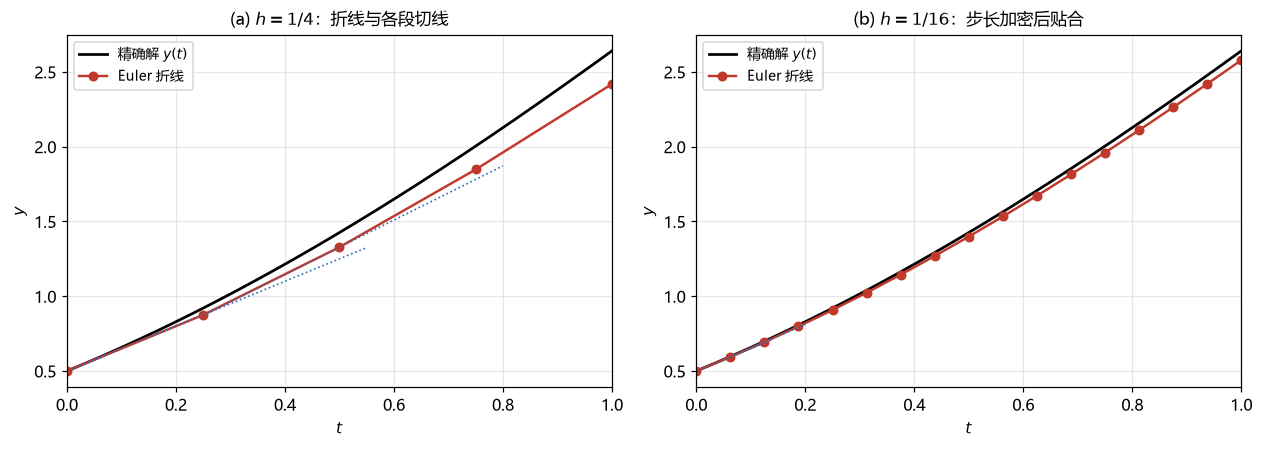

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11.6, 4.2))
tt = np.linspace(0.0, 1.0, 400)

for a, h, tag in ((ax[0], 0.25, "(a) $h=1/4$：折线与各段切线"),
                  (ax[1], 1.0 / 16.0, "(b) $h=1/16$：步长加密后贴合")):
    ts, ys, nfe = euler(f, 0.0, 0.5, 1.0, h)
    a.plot(tt, exact(tt), "k-", lw=1.8, label="精确解 $y(t)$")
    a.plot(ts, ys, "o-", color="#c0392b", lw=1.6, ms=5.5, label="Euler 折线")
    for k in range(min(2, len(ts) - 1)):
        s = np.linspace(ts[k], ts[k] + 2.2 * h, 50)
        a.plot(s, ys[k] + (s - ts[k]) * f(ts[k], ys[k]), ":", color="#2c6fbb", lw=1.1)
    a.set_title(tag, fontsize=11)
    a.set_xlabel("$t$"); a.set_ylabel("$y$")
    a.set_xlim(0, 1.0); a.legend(fontsize=9, loc="upper left"); a.grid(alpha=.3)
    print(f"h=1/{round(1/h):<3} 段数={len(ts)-1:>2}  n_fe={nfe:>2}  "
          f"末点 y={ys[-1]:.4f}  精确值={float(exact(1.0)):.4f}")

fig.tight_layout()
fig.savefig("图片/图3.1.1-1-Euler折线与精确解.png", facecolor="white")
plt.show()

左图里折线由四段直线组成，每段的斜率等于精确解在该段起点处的导数；由于解处处上凸，
切线位于曲线上方，而折线沿切线走水平距离 $h$，落点落在曲线下方——整条折线位于精确解的下方。
右图把步长减到 $1/16$，段数由 4 变 16，贴合明显更紧，但仍在下方。

把 $h=1/4$ 的节点值列成表 1（正文表 1），并写入 `数据/表3.1.1-1-折线节点.csv`。

In [4]:
h = 0.25
ts, ys, nfe = euler(f, 0.0, 0.5, 1.0, h)
rows = [dict(n=i, t=float(ts[i]), y_n=float(ys[i]), y_exact=float(exact(ts[i])))
        for i in range(len(ts))]

with open("数据/表3.1.1-1-折线节点.csv", "w", encoding="utf-8-sig") as fp:
    fp.write("n,t,y_n,y_exact\n")
    for r in rows:
        fp.write(f"{r['n']},{r['t']:.4f},{r['y_n']:.10f},{r['y_exact']:.10f}\n")

print(f"{'n':>2}{'t_n':>8}{'y_n':>12}{'y(t_n)':>12}")
for r in rows:
    print(f"{r['n']:>2}{r['t']:>8.2f}{r['y_n']:>12.4f}{r['y_exact']:>12.4f}")
print("已保存 数据/表3.1.1-1-折线节点.csv")

 n     t_n         y_n      y(t_n)
 0    0.00      0.5000      0.5000
 1    0.25      0.8750      0.9205
 2    0.50      1.3281      1.4256
 3    0.75      1.8477      2.0040
 4    1.00      2.4189      2.6409
已保存 数据/表3.1.1-1-折线节点.csv


从表 1 可以看到两件事：每个节点的数值都小于精确值，与“折线在下方”的几何判断一致；
$t$ 越大，两者的差距越明显——折线的偏离是逐步累积的，不是每步一个固定量。
**差距随 $h$ 怎样变化、按什么速率趋于零，属于 3.1.3，本节不作结论。**

## 实验 2　一步手算

取最简单的问题 $y'=-y$、$y(0)=1$、$h=0.5$，只走一步。
手算：$f(t_0,y_0)=-1$，$y_1=y_0+h f(t_0,y_0)=1+0.5\times(-1)=0.5$。
下面的代码把同一件事交给程序做，并核对 $n_{\mathrm{fe}}$ 是否等于 $1$。

In [5]:
def g(t, y):
    return -y


t0, y0, T, h = 0.0, 1.0, 0.5, 0.5
ts1, ys1, nfe1 = euler(g, t0, y0, T, h)
print(f"t  = {ts1.tolist()}")
print(f"y  = {ys1.tolist()}")
print(f"n_fe = {nfe1}（一步只求值一次）")
print(f"精确值 y(0.5) = {math.exp(-0.5):.10f}，Euler 给 {ys1[-1]:.10f}")

# 再走两步看累积：这一步的差会被下一步继续带下去
ts2, ys2, nfe2 = euler(g, t0, y0, 1.0, 0.5)
print(f"走到 t=1：y = {ys2.tolist()}，精确值 e^-1 = {math.exp(-1):.10f}，n_fe = {nfe2}")

t  = [0.0, 0.5]
y  = [1.0, 0.5]
n_fe = 1（一步只求值一次）
精确值 y(0.5) = 0.6065306597，Euler 给 0.5000000000
走到 t=1：y = [1.0, 0.5, 0.25]，精确值 e^-1 = 0.3678794412，n_fe = 2


这一步的差（约 $0.1065$）不是程序错误：Euler 用切线代替了曲线，单步之内就留下了截断。
**它有多大、沿步数累积后变成多少，是 3.1.3 的内容**；本节只把格式与实现对齐。

## 小结

- 正文 (17) 的格式在代码里就是 `y = y + h * f(t, y)` 这一行，每步一次右端求值，故 $n_{\mathrm{fe}}=M$。
- 步长要在取整后修正，否则最后一层不在 $T$ 上（见 `euler` 里的 `h = (T - t0) / M`）。
- 折线的几何行为（在精确解下方、步长加密后贴合更紧）可以直接从图上读出，与正文 2.2 节的判断一致。
- 误差阶、误差界、稳定性与计算成本属 3.1.3，本节不涉及。

**输出位置**：图片 → `图片/图3.1.1-1-Euler折线与精确解.png`；数据 → `数据/表3.1.1-1-折线节点.csv`、`数据/ch3_1_1_results.json`。

In [6]:
summary = dict(
    setup=dict(t0=0.0, T=1.0, y0=0.5),
    nodes_h025=[(r["t"], r["y_n"], r["y_exact"]) for r in rows],
    hand=dict(t=ts1.tolist(), y=ys1.tolist(), nfe=int(nfe1)),
)
with open("数据/ch3_1_1_results.json", "w", encoding="utf-8") as fp:
    json.dump(summary, fp, ensure_ascii=False, indent=1)

print("已保存 数据/ch3_1_1_results.json")
print("图片目录:", sorted(f for f in os.listdir("图片") if f.startswith("图3.1.1")))

已保存 数据/ch3_1_1_results.json
图片目录: ['图3.1.1-1-Euler折线与精确解.png', '图3.1.1-1-Euler折线与精确解.svg', '图3.1.1-2-收敛阶.png', '图3.1.1-3-误差传播.png', '图3.1.1-3-误差传播.svg']
